# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Indah Putri Lestari
- **Email:** indahptr401@gmail.com
- **ID Dicoding:** indah_putri_lestari

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang menyumbang revenue terbesar (Top 10) sepanjang tahun 2017, dan bagaimana tren revenue bulanannya (Month-over-Month) dari Januari 2017 sampai Agustus 2018?
- **Pertanyaan 2:** Berapa selisih rata-rata review score antara pesanan yang tiba tepat waktu dan yang terlambat selama periode Januari 2017 sampai Agustus 2018, dan di 5 state mana persentase keterlambatannya paling tinggi?
- **Pertanyaan 3:** Bagaimana sebaran pelanggan unik pada tiap segmen RFM (Recency, Frequency, Monetary) berdasarkan transaksi Januari 2017 sampai Agustus 2018, dan segmen mana yang menyumbang revenue terbesar?

## Import Semua Packages/Library yang Digunakan

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Data Wrangling

### Gathering Data

#### Load df tabel

In [ ]:
customers_df = pd.read_csv("customers_dataset.csv")
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [ ]:
orders_df = pd.read_csv("orders_dataset.csv")
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
items_df = pd.read_csv("order_items_dataset.csv")
items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
products_df = pd.read_csv("products_dataset.csv")
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [ ]:
category_df = pd.read_csv("product_category_name_translation.csv")
category_df.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [ ]:
reviews_df = pd.read_csv("order_reviews_dataset.csv")
reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [ ]:
sellers_df = pd.read_csv("sellers_dataset.csv")
sellers_df.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [ ]:
geolocation_df = pd.read_csv("geolocation_dataset.csv")
geolocation_df.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [ ]:
payments_df = pd.read_csv("order_payments_dataset.csv")
payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


**Insight:**
- Dataset terdiri dari 9 tabel yang saling terhubung. Tabel `orders_df` menjadi pusat relasi: `order_id` terhubung ke `items_df`, `reviews_df`, dan `payments_df`, sedangkan `customer_id` terhubung ke `customers_df`.
- Tabel `items_df` menghubungkan pesanan ke `products_df` (lewat `product_id`) dan `sellers_df` (lewat `seller_id`). Kolom `price` di tabel ini dipakai sebagai dasar perhitungan revenue.
- Nama kategori produk masih berbahasa Portugis, sehingga perlu digabung dengan `category_df` untuk mendapatkan nama bahasa Inggris.
- Tabel `geolocation_df` berisi lebih dari 1 juta baris dengan banyak titik untuk zip code yang sama, sehingga perlu diagregasi sebelum dipakai untuk peta.

### Assessing Data

#### Identifying missing value problem

In [ ]:
tabel_dinilai = {
    "orders_df": orders_df, "items_df": items_df, "products_df": products_df,
    "reviews_df": reviews_df, "customers_df": customers_df,
    "sellers_df": sellers_df, "geolocation_df": geolocation_df,
}

for nama, df in tabel_dinilai.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]
    print(f"=== {nama} ===")
    print(missing if not missing.empty else "Tidak ada missing value")
    print()

=== orders_df ===
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

=== items_df ===
Tidak ada missing value

=== products_df ===
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

=== reviews_df ===
review_comment_title      87656
review_comment_message    58247
dtype: int64

=== customers_df ===
Tidak ada missing value

=== sellers_df ===
Tidak ada missing value

=== geolocation_df ===
Tidak ada missing value



#### Identifying invalid data type problem

In [ ]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [ ]:
reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [ ]:
items_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


#### Identifying duplicate data problem

In [ ]:
for nama, df in tabel_dinilai.items():
    print(f"{nama:16s} -> duplikasi baris: {df.duplicated().sum():,}")

print("\norder_id unik di orders_df  :", orders_df.order_id.is_unique)
print("review_id duplikat          :", reviews_df.review_id.duplicated().sum())
print("order_id duplikat (reviews) :", reviews_df.order_id.duplicated().sum())
print("customer_id unik            :", customers_df.customer_id.nunique())
print("customer_unique_id          :", customers_df.customer_unique_id.nunique())

orders_df        -> duplikasi baris: 0
items_df         -> duplikasi baris: 0
products_df      -> duplikasi baris: 0
reviews_df       -> duplikasi baris: 0
customers_df     -> duplikasi baris: 0
sellers_df       -> duplikasi baris: 0
geolocation_df   -> duplikasi baris: 261,831

order_id unik di orders_df  : True
review_id duplikat          : 814
order_id duplikat (reviews) : 551
customer_id unik            : 99441
customer_unique_id          : 96096


#### Identifying inconsistent value problem

In [ ]:
# Status pesanan vs tanggal tiba
print(orders_df.order_status.value_counts())
print("\ndelivered tapi tanggal tiba kosong   :", len(orders_df[(orders_df.order_status == "delivered") & (orders_df.order_delivered_customer_date.isna())]))
print("bukan delivered tapi tanggal tiba ada:", len(orders_df[(orders_df.order_status != "delivered") & (orders_df.order_delivered_customer_date.notna())]))

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

delivered tapi tanggal tiba kosong   : 8
bukan delivered tapi tanggal tiba ada: 6


In [ ]:
# Kategori produk tanpa terjemahan
kategori_produk = set(products_df.product_category_name.dropna().unique())
kategori_terjemahan = set(category_df.product_category_name.unique())
print("Kategori tanpa terjemahan:", kategori_produk - kategori_terjemahan)

Kategori tanpa terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


In [ ]:
# Sebaran pesanan per bulan (dasar pembatasan periode analisis)
purchase_month = pd.to_datetime(orders_df.order_purchase_timestamp).dt.to_period("M")
purchase_month.value_counts().sort_index()

,count
order_purchase_timestamp,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


#### Identifying outlier problem

In [ ]:
items_df[["price", "freight_value"]].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [ ]:
products_df[["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]].describe()

,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32949.000000,32949.000000,32949.000000,32949.000000
mean,2276.472488,30.815078,16.937661,23.196728
std,4282.038731,16.914458,13.637554,12.079047
min,0.000000,7.000000,2.000000,6.000000
25%,300.000000,18.000000,8.000000,15.000000
50%,700.000000,25.000000,13.000000,20.000000
75%,1900.000000,38.000000,21.000000,30.000000
max,40425.000000,105.000000,105.000000,118.000000


**Steps to Take:**
- **Missing value `orders_df`:** tiga kolom tanggal memiliki nilai kosong, umumnya pada pesanan yang belum selesai atau dibatalkan. Analisis hanya memakai pesanan berstatus `delivered` dengan tanggal tiba terisi, sehingga baris lainnya dibuang.
- **Missing value `products_df`:** `product_category_name` kosong pada 610 produk. Isi dengan label `unknown` agar revenue-nya tetap terhitung. Dua produk tanpa berat dan dimensi tidak dipakai analisis, jadi dibiarkan.
- **Missing value `reviews_df`:** kolom judul dan isi komentar banyak yang kosong, tetapi tidak dipakai untuk menjawab pertanyaan bisnis sehingga dibiarkan.
- **Invalid data type:** kolom tanggal pada `orders_df`, `reviews_df`, dan `items_df` masih bertipe `object`, perlu diubah menjadi `datetime`.
- **Duplicate data `reviews_df`:** pertahankan satu review per `order_id` (review terbaru berdasarkan `review_answer_timestamp`) agar saat merge tidak ada pesanan yang terhitung ganda.
- **Duplicate data `geolocation_df`:** hapus baris duplikat, lalu agregasi per `geolocation_zip_code_prefix` (rata-rata lat/lng) agar satu zip code hanya punya satu titik untuk peta.
- **Inconsistent value:** pesanan `delivered` tanpa tanggal tiba dibuang. Kategori `pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos` diterjemahkan manual agar tidak menjadi NaN saat merge dengan `category_df`.
- **Data di luar periode analisis:** pesanan sebelum Januari 2017 dan setelah Agustus 2018 difilter keluar.
- **Outlier `items_df`:** `price` dan `freight_value` yang tinggi tidak dibuang karena valid sebagai produk bernilai tinggi. Dicatat sebagai keterbatasan dan ditangani saat visualisasi (misalnya memakai median atau menampilkan tanpa outlier).
- **Inaccurate value `products_df`:** `product_weight_g` bernilai 0 tidak masuk akal, tetapi kolom ini tidak dipakai di analisis sehingga tidak diperbaiki.

**Insight:**
- Tabel `orders_df` memiliki missing value di tiga kolom tanggal (160, 1.783, dan 2.965 baris). Sebanyak 96.478 dari 99.441 pesanan (sekitar 97%) berstatus `delivered`, sehingga mayoritas pesanan tetap dapat dipakai untuk analisis ketepatan waktu.
- Ditemukan inkonsistensi status dan tanggal: 8 pesanan `delivered` tanpa tanggal tiba, dan 6 pesanan non-delivered yang justru memiliki tanggal tiba.
- Kolom `product_category_name` memiliki 610 missing value, dan dua kategori (`pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`) tidak memiliki terjemahan bahasa Inggris.
- Seluruh kolom tanggal masih bertipe `object` dan harus dikonversi sebelum selisih hari dapat dihitung.
- Tabel `geolocation_df` memiliki 261.831 baris duplikat dan banyak titik berbeda untuk zip code yang sama, sehingga perlu diagregasi sebelum dipakai untuk peta.
- Tabel `reviews_df` memiliki 814 `review_id` dan 551 `order_id` yang berulang, sehingga perlu dideduplikasi agar satu pesanan tidak terhitung ganda saat di-merge.
- Terdapat 99.441 `customer_id` tetapi hanya 96.096 `customer_unique_id`, artinya sebagian pelanggan melakukan lebih dari satu pesanan. Untuk RFM (Pertanyaan 3), pelanggan harus diidentifikasi dengan `customer_unique_id`.
- Jumlah pesanan 2016 dan September-Oktober 2018 sangat sedikit (349 pesanan, kurang dari 0,4%), sehingga periode analisis dibatasi pada Januari 2017 sampai Agustus 2018.
- Nilai `price` (maks 6.735) dan `freight_value` (maks 409,68) jauh di atas median (74,99 dan 16,26), tetapi dianggap valid sebagai produk atau pengiriman bernilai tinggi.

### Cleaning Data

#### Fixing invalid data type problem

In [ ]:
datetime_columns = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in datetime_columns:
    orders_df[column] = pd.to_datetime(orders_df[column])

In [ ]:
for column in ["review_creation_date", "review_answer_timestamp"]:
    reviews_df[column] = pd.to_datetime(reviews_df[column])

In [ ]:
items_df["shipping_limit_date"] = pd.to_datetime(items_df["shipping_limit_date"])

In [ ]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [ ]:
print(reviews_df[["review_creation_date", "review_answer_timestamp"]].dtypes)
print(items_df[["shipping_limit_date"]].dtypes)

review_creation_date       datetime64[ns]
review_answer_timestamp    datetime64[ns]
dtype: object
shipping_limit_date    datetime64[ns]
dtype: object


#### Fixing missing value problem

In [ ]:
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")

In [ ]:
products_df.isna().sum()

,0
product_id,0
product_category_name,0
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [ ]:
print("Sebelum:", len(orders_df))
orders_df = orders_df.dropna(subset=["order_delivered_customer_date"])
print("Sesudah:", len(orders_df))

Sebelum: 99441
Sesudah: 96476


In [ ]:
orders_df.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,14
order_delivered_carrier_date,1
order_delivered_customer_date,0
order_estimated_delivery_date,0


#### Fixing duplicate data problem

In [ ]:
reviews_df = reviews_df.sort_values("review_answer_timestamp").drop_duplicates(subset="order_id", keep="last")

In [ ]:
print("Jumlah baris          :", len(reviews_df))
print("order_id duplikat     :", reviews_df.order_id.duplicated().sum())

Jumlah baris          : 98673
order_id duplikat     : 0


In [ ]:
geolocation_df.drop_duplicates(inplace=True)
print("Jumlah baris:", len(geolocation_df))

Jumlah baris: 738332


In [ ]:
geolocation_df = geolocation_df.groupby("geolocation_zip_code_prefix").agg({
    "geolocation_lat": "mean",
    "geolocation_lng": "mean",
    "geolocation_state": lambda x: x.mode()[0]
}).reset_index()

In [ ]:
print(geolocation_df.geolocation_zip_code_prefix.is_unique)
geolocation_df.head()

True


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_state
0,1001,-23.550227,-46.634039,SP
1,1002,-23.547657,-46.634991,SP
2,1003,-23.549000,-46.635582,SP
3,1004,-23.549829,-46.634792,SP
4,1005,-23.549547,-46.636406,SP


#### Fixing inconsistent value problem

In [ ]:
print("Sebelum:", len(orders_df))
orders_df = orders_df[orders_df.order_status == "delivered"]
print("Sesudah:", len(orders_df))

Sebelum: 96476
Sesudah: 96470


In [ ]:
kategori_baru = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos", "unknown"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_and_food_preparers", "unknown"]
})
category_df = pd.concat([category_df, kategori_baru], ignore_index=True)

In [ ]:
set(products_df.product_category_name.unique()) - set(category_df.product_category_name.unique())

set()

#### Fixing data di luar periode analisis

In [ ]:
print("Sebelum:", len(orders_df))
orders_df = orders_df[
    (orders_df.order_purchase_timestamp >= "2017-01-01") &
    (orders_df.order_purchase_timestamp < "2018-09-01")
]
print("Sesudah:", len(orders_df))

Sebelum: 96470
Sesudah: 96203


In [ ]:
print(orders_df.order_purchase_timestamp.min())
print(orders_df.order_purchase_timestamp.max())

2017-01-05 11:56:06
2018-08-29 15:00:37


**Insight:**
- Seluruh kolom tanggal pada `orders_df`, `reviews_df`, dan `items_df` sudah diubah menjadi `datetime`, sehingga selisih hari (misalnya keterlambatan pengiriman) dapat dihitung.
- Pesanan tanpa tanggal tiba (2.965 baris) dan pesanan non-delivered dibuang, sehingga tersisa 96.470 pesanan `delivered`. Setelah difilter ke periode Januari 2017 sampai Agustus 2018, tersisa 96.203 pesanan.
- Review duplikat dibersihkan menjadi 98.673 baris sehingga satu pesanan hanya memiliki satu review terbaru, dan `geolocation_df` dipadatkan dari lebih dari 1 juta baris menjadi satu titik koordinat per zip code.
- Kategori produk kosong diberi label `unknown`, dan dua kategori tanpa terjemahan sudah ditambahkan ke `category_df`, sehingga tidak ada kategori yang menjadi NaN saat merge.
- Sisa missing value di `orders_df` (`order_approved_at` dan `order_delivered_carrier_date`) tidak dibersihkan karena kolom tersebut tidak dipakai untuk menjawab pertanyaan bisnis.
- Outlier pada `price` dan `freight_value` tidak dihapus karena merupakan nilai valid untuk produk atau pengiriman bernilai tinggi. Hal ini dicatat sebagai keterbatasan analisis.
- Tabel `items_df` dan `reviews_df` belum difilter periode secara langsung. Filter akan otomatis berlaku saat kedua tabel digabung (merge) dengan `orders_df` pada tahap EDA.

## Exploratory Data Analysis (EDA)

### Explore `orders_df`

In [ ]:
orders_df = orders_df.copy()
orders_df.sample(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
41465,bf36b37f7569ba312ffe5abb914fc5bf,e42b74db1e519a05ae7d6c09a77aa19e,delivered,2018-02-23 01:23:42,2018-02-27 04:31:09,2018-02-28 02:46:40,2018-03-06 22:21:48,2018-03-09
5119,1264bdfa22a4cca2beb66c1f542e7f5c,54c196a036b31e7af51aa30178be083e,delivered,2017-09-19 23:12:15,2017-09-19 23:25:35,2017-09-25 20:37:42,2017-09-26 10:52:12,2017-09-29
71569,8c7304b887c62d8b229df046f90e44f4,0519861eea334b9c63211d1a02c1a484,delivered,2017-12-05 13:59:56,2017-12-05 14:31:04,2017-12-06 03:51:56,2018-01-05 13:22:39,2017-12-28
90075,8a22f6bd4ea83c9fcdbf0235d55ea061,02f2ea36613d01ae6561f97fd88d632a,delivered,2017-09-25 15:09:03,2017-09-25 15:24:53,2017-09-27 21:05:08,2017-10-06 17:22:11,2017-10-18
28212,048c6b6617c20f59a0ac4e9a348667e9,260e71f4624185a5b0e2197b0db65ed0,delivered,2018-01-13 20:02:47,2018-01-13 20:09:35,2018-01-18 20:48:41,2018-01-29 15:22:51,2018-02-07


In [ ]:
# Lama pengiriman (hari) dari pembelian sampai tiba
delivery_time = orders_df["order_delivered_customer_date"] - orders_df["order_purchase_timestamp"]
orders_df["delivery_time"] = np.ceil(delivery_time.dt.total_seconds() / 86400)

# Selisih tanggal tiba terhadap estimasi (positif = terlambat)
delay = orders_df["order_delivered_customer_date"] - orders_df["order_estimated_delivery_date"]
orders_df["delay_days"] = np.ceil(delay.dt.total_seconds() / 86400)

In [ ]:
orders_df["delivery_status"] = np.select(
    [orders_df["delay_days"] <= 0, orders_df["delay_days"] <= 3],
    ["Tepat waktu", "Telat 1-3 hari"],
    default="Telat >3 hari"
)
orders_df["is_late"] = orders_df["delay_days"] > 0
orders_df["order_month"] = orders_df["order_purchase_timestamp"].dt.strftime("%Y-%m")
orders_df.sample(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,delay_days,delivery_status,is_late,order_month
23641,a4e584c6dc40947a851d93c60fe9c50c,6ca380abc4115fc796b443dcea044d0a,delivered,2018-08-05 11:19:24,2018-08-05 11:30:17,2018-08-06 09:17:00,2018-08-09 01:03:23,2018-08-09,4.0,1.0,Telat 1-3 hari,True,2018-08
22259,865897de02d9ded27e7598dc5013f98e,040d25956c9d082b572f1482b34630ce,delivered,2018-08-14 22:42:02,2018-08-14 22:55:35,2018-08-17 07:43:00,2018-08-27 19:36:49,2018-09-24,13.0,-27.0,Tepat waktu,False,2018-08
55922,5d8e9c0a711b826b72298f9abeb269cd,b21ff624eaefac438d7923cd142bd9c5,delivered,2017-02-06 12:19:55,2017-02-08 03:15:13,2017-02-08 11:41:17,2017-02-13 15:12:46,2017-03-01,8.0,-15.0,Tepat waktu,False,2017-02
12702,42fdf880ba16b47b59251dd489d4441a,15fd6fb8f8312dbb4674e4518d6fa3b3,delivered,2018-05-21 13:59:17,2018-05-21 16:14:41,2018-05-22 11:46:00,2018-06-01 21:44:53,2018-06-13,12.0,-11.0,Tepat waktu,False,2018-05
32735,0eaa4845a6182d6b72de720fb976abd4,4d7f34d701f198e39e1c0cd92c3ee12c,delivered,2017-01-17 18:44:09,2017-01-17 18:55:20,2017-01-18 10:55:18,2017-01-27 12:13:56,2017-03-07,10.0,-38.0,Tepat waktu,False,2017-01


In [ ]:
orders_df[["delivery_time", "delay_days"]].describe()

,delivery_time,delay_days
count,96203.000000,96203.000000
mean,13.073844,-10.807969
std,9.535548,10.088942
min,1.000000,-146.000000
25%,7.000000,-16.000000
50%,11.000000,-11.000000
75%,16.000000,-6.000000
max,210.000000,189.000000


In [ ]:
orders_df.delivery_status.value_counts()

,count
delivery_status,
Tepat waktu,88381
Telat >3 hari,5162
Telat 1-3 hari,2660


In [ ]:
orders_df.delivery_status.value_counts(normalize=True).round(4) * 100

,proportion
delivery_status,
Tepat waktu,91.87
Telat >3 hari,5.37
Telat 1-3 hari,2.76


### Explore `items_df`

In [ ]:
items_df.sample(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
8763,140d9953eb16589e277967bbfcdf7ac5,1,bdf5efab9b8b85e6a49603007646f763,5f3ae9136c875522250f8184f253413a,2018-08-23 12:50:31,14.95,7.39
17784,28ccc6df03d720b1c01c91ce78025016,2,c0704b7b41d23540e8576c5e84484dcb,aac51c486b672a9850d59f3e84b1cf88,2018-08-23 12:50:14,37.00,15.36
59787,8836e9da58524060994ead4403874ad3,1,7d33844ffd50c5fb265a1e0ba03d9470,7299e27ed73d2ad986de7f7c77d919fa,2018-01-16 03:33:54,60.00,15.17
103933,ec0bc44edd6eff22baea2a84bf6c0404,1,66484d3ad6c8fcd55265bfdb060fc8cc,05ff92fedb5be47920fea08e501238b9,2017-03-24 09:09:50,328.00,14.88
72568,a57e4cb553fb02d95f5acfab1d068804,1,c87d290a69f27d78e303df61eb85409b,2953ce3a88f5e3c3b696d77fc9e4c8eb,2018-02-13 02:55:45,39.00,7.78


In [ ]:
items_df[["price", "freight_value"]].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [ ]:
print("Jumlah order unik di items_df :", items_df.order_id.nunique())
print("Jumlah produk unik            :", items_df.product_id.nunique())
print("Jumlah seller unik            :", items_df.seller_id.nunique())

Jumlah order unik di items_df : 98666
Jumlah produk unik            : 32951
Jumlah seller unik            : 3095


### Explore `products_df` & `category_df`

In [ ]:
products_category_df = pd.merge(
    left=products_df[["product_id", "product_category_name"]],
    right=category_df,
    how="left",
    on="product_category_name"
)
products_category_df.head()

,product_id,product_category_name,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares


In [ ]:
products_category_df.product_category_name_english.isna().sum()

np.int64(0)

In [ ]:
products_category_df.product_category_name_english.value_counts().head(10)

,count
product_category_name_english,
bed_bath_table,3029
sports_leisure,2867
furniture_decor,2657
health_beauty,2444
housewares,2335
auto,1900
computers_accessories,1639
toys,1411
watches_gifts,1329


### Explore `reviews_df`

In [ ]:
reviews_df.sample(5)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
17319,9f4589ea1545cb869411272168acc74c,bd4ff7998fcfa299d9275e288adf4efa,1,NaN,NaN,2018-04-11,2018-04-11 13:20:18
75324,f7e02b7acd071bee77d7bfe978c92f0c,79164f97a0f684659f0881551ed73a2e,3,NaN,Produto recebido após 1 mês de efetuado o pedi...,2018-03-14,2018-03-15 12:26:48
30331,9cd0e018fa0fef10981f372d76e6fe99,c72a06dbd2869dbfa3dc93ca4f262f37,5,Muito bom,Produto entregue antes do prazo.,2018-08-31,2018-09-03 08:09:09
51162,d200688452259b8a3590654e45b3b934,35681d761149a472aa05d9fe484c61b3,1,NaN,Estou indignado esperando meus produtos veio s...,2017-12-07,2017-12-07 21:42:57
96385,25785cff4c7243da038683a3e8fdaf34,e225050f709a0409b3a30c63fa35c6da,3,Bom,"Gostei do produto será muito útil, recomendo a...",2018-08-15,2018-08-19 00:47:28


In [ ]:
reviews_df.review_score.value_counts().sort_index()

,count
review_score,
1,11363
2,3131
3,8133
4,19038
5,57008


In [ ]:
print("Rata-rata review score:", round(reviews_df.review_score.mean(), 2))

Rata-rata review score: 4.09


### Explore `customers_df`

In [ ]:
customers_df.sample(5)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
60038,0fae07bb4b1670e3da7d768c54f59464,ef589c64edf26fb431b56db8f6515fad,66083,belem,PA
77519,ad6acb9e0ffc35906b64d488bbdb6d5a,ca50300f552f1bc9b5aa898a29382d69,28013,campos dos goytacazes,RJ
42388,4daf9bdbb2f515d19c4a054881982674,8639ba758371b0ef0e3d8264ac944b2c,3127,sao paulo,SP
16763,fd8a555de51282eecd0be08daf81f3f7,2b6e79bf196b664b2eb9f2004fad4244,1153,sao paulo,SP
79995,35148f0d009a1f17f54bdadaf07a4bf0,2dc14a6827e04328bea6dfd07ebf5ae4,4204,sao paulo,SP


In [ ]:
customers_df.groupby(by="customer_state").customer_unique_id.nunique().sort_values(ascending=False).head(10)

,customer_unique_id
customer_state,
SP,40302
RJ,12384
MG,11259
RS,5277
PR,4882
SC,3534
BA,3277
DF,2075
ES,1964


### Explore all data

#### Menggabungkan data `orders_df`, `customers_df`, dan `reviews_df`

In [ ]:
orders_customers_df = pd.merge(
    left=orders_df,
    right=customers_df,
    how="left",
    left_on="customer_id",
    right_on="customer_id"
)
orders_customers_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,delay_days,delivery_status,is_late,order_month,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,9.0,-7.0,Tepat waktu,False,2017-10,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,14.0,-5.0,Tepat waktu,False,2018-07,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,10.0,-17.0,Tepat waktu,False,2018-08,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,14.0,-12.0,Tepat waktu,False,2017-11,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,3.0,-9.0,Tepat waktu,False,2018-02,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [ ]:
orders_reviews_df = pd.merge(
    left=orders_customers_df,
    right=reviews_df[["order_id", "review_score"]],
    how="left",
    on="order_id"
)
orders_reviews_df.review_score.isna().sum()

np.int64(643)

#### Menggabungkan data `items_df`, `products_df`, dan `category_df`

In [ ]:
items_products_df = pd.merge(
    left=items_df,
    right=products_df[["product_id", "product_category_name"]],
    how="left",
    on="product_id"
)
items_products_df = pd.merge(
    left=items_products_df,
    right=category_df,
    how="left",
    on="product_category_name"
)
items_products_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools


#### Menghubungkan semua data menjadi `all_df`

In [ ]:
all_df = pd.merge(
    left=orders_reviews_df,
    right=items_products_df[["order_id", "order_item_id", "price", "freight_value", "product_category_name_english"]],
    how="inner",
    on="order_id"
)
all_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,delay_days,delivery_status,is_late,order_month,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,review_score,order_item_id,price,freight_value,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,9.0,-7.0,Tepat waktu,False,2017-10,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,4.0,1,29.99,8.72,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,14.0,-5.0,Tepat waktu,False,2018-07,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,4.0,1,118.70,22.76,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,10.0,-17.0,Tepat waktu,False,2018-08,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,5.0,1,159.90,19.22,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,14.0,-12.0,Tepat waktu,False,2017-11,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,5.0,1,45.00,27.20,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,3.0,-9.0,Tepat waktu,False,2018-02,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,5.0,1,19.90,8.72,stationery


In [ ]:
print("Jumlah baris all_df         :", len(all_df))
print("Jumlah order unik di all_df :", all_df.order_id.nunique())
print("Jumlah order di orders_df   :", len(orders_df))

Jumlah baris all_df         : 109872
Jumlah order unik di all_df : 96203
Jumlah order di orders_df   : 96203


In [ ]:
all_df.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,15
order_delivered_carrier_date,1
order_delivered_customer_date,0
order_estimated_delivery_date,0
delivery_time,0
delay_days,0


### Explore revenue per kategori produk dan tren bulanan

In [ ]:
category_revenue_2017_df = (
    all_df[all_df["order_purchase_timestamp"].dt.year == 2017]
    .groupby("product_category_name_english")
    .agg(order_count=("order_id", "nunique"), revenue=("price", "sum"))
    .sort_values("revenue", ascending=False)
)
category_revenue_2017_df["revenue_share_pct"] = (
    category_revenue_2017_df["revenue"] / category_revenue_2017_df["revenue"].sum() * 100
).round(2)
category_revenue_2017_df.head(10)

,order_count,revenue,revenue_share_pct
product_category_name_english,,,
bed_bath_table,4423,490596.92,8.23
watches_gifts,2073,475610.71,7.98
health_beauty,3305,473833.00,7.95
sports_leisure,3539,435495.14,7.30
computers_accessories,2546,391786.29,6.57
cool_stuff,2161,381414.30,6.40
furniture_decor,3111,324587.60,5.44
toys,2404,299056.71,5.02
garden_tools,1934,256949.20,4.31


In [ ]:
print("Total share Top 10 kategori (%):", category_revenue_2017_df.head(10).revenue_share_pct.sum().round(2))

Total share Top 10 kategori (%): 63.13


In [ ]:
monthly_revenue_df = all_df.groupby("order_month").agg(
    order_count=("order_id", "nunique"),
    revenue=("price", "sum")
)
monthly_revenue_df["mom_growth_pct"] = (monthly_revenue_df["revenue"].pct_change() * 100).round(2)
monthly_revenue_df

,order_count,revenue,mom_growth_pct
order_month,,,
2017-01,750,111798.36,NaN
2017-02,1653,234223.40,109.51
2017-03,2546,359198.85,53.36
2017-04,2303,340669.68,-5.16
2017-05,3545,489159.25,43.59
2017-06,3135,421923.37,-13.75
2017-07,3872,481604.52,14.15
2017-08,4193,554699.70,15.18
2017-09,4150,607399.67,9.50


### Explore review score dan keterlambatan pengiriman

Satu pesanan bisa terdiri dari beberapa item sehingga muncul beberapa baris di `all_df`. Untuk analisis level pesanan, data dideduplikasi per `order_id` agar satu pesanan tidak dihitung berkali-kali.

In [ ]:
orders_unique_df = all_df.drop_duplicates(subset="order_id")
len(orders_unique_df)

96203

In [ ]:
orders_unique_df.groupby("is_late").agg(
    order_count=("order_id", "nunique"),
    avg_review_score=("review_score", "mean")
).round(2)

,order_count,avg_review_score
is_late,,
False,88381,4.29
True,7822,2.57


In [ ]:
avg_score = orders_unique_df.groupby("is_late").review_score.mean()
print("Rata-rata review (tepat waktu):", round(avg_score[False], 2))
print("Rata-rata review (terlambat)  :", round(avg_score[True], 2))
print("Selisih                       :", round(avg_score[False] - avg_score[True], 2))

Rata-rata review (tepat waktu): 4.29
Rata-rata review (terlambat)  : 2.57
Selisih                       : 1.73


In [ ]:
orders_unique_df.groupby("delivery_status").agg(
    order_count=("order_id", "nunique"),
    avg_review_score=("review_score", "mean")
).round(2)

,order_count,avg_review_score
delivery_status,,
Telat 1-3 hari,2660,3.77
Telat >3 hari,5162,1.94
Tepat waktu,88381,4.29


In [ ]:
state_late_df = orders_unique_df.groupby("customer_state").agg(
    order_count=("order_id", "nunique"),
    late_count=("is_late", "sum"),
    late_pct=("is_late", lambda x: round(x.mean() * 100, 2))
).sort_values("late_pct", ascending=False)
state_late_df.head(10)

,order_count,late_count,late_pct
customer_state,,,
AL,396,95,23.99
MA,713,140,19.64
PI,475,76,16.00
CE,1273,196,15.40
SE,332,51,15.36
BA,3253,457,14.05
RJ,12310,1664,13.52
TO,274,35,12.77
RR,40,5,12.50


State dengan jumlah pesanan sangat sedikit bisa menghasilkan persentase yang tidak representatif, sehingga peringkat dibatasi pada state dengan minimal 100 pesanan.

In [ ]:
state_late_df[state_late_df["order_count"] >= 100].head(5)

,order_count,late_count,late_pct
customer_state,,,
AL,396,95,23.99
MA,713,140,19.64
PI,475,76,16.00
CE,1273,196,15.40
SE,332,51,15.36


### Explore frekuensi pembelian pelanggan

In [ ]:
frequency_df = all_df.groupby("customer_unique_id").order_id.nunique()
frequency_df.value_counts().sort_index()

,count
order_id,
1,90307
2,2562
3,180
4,28
5,9
6,5
7,3
9,1
15,1


In [ ]:
pd.cut(
    frequency_df,
    bins=[0, 1, 2, np.inf],
    labels=["1 kali", "2 kali", "3 kali atau lebih"]
).value_counts(normalize=True).mul(100).round(2)

,proportion
order_id,
1 kali,97.00
2 kali,2.75
3 kali atau lebih,0.24


In [ ]:
print("Pelanggan unik                :", len(frequency_df))
print("Pelanggan yang beli lebih 1x (%):", round((frequency_df > 1).mean() * 100, 2))

Pelanggan unik                : 93096
Pelanggan yang beli lebih 1x (%): 3.0


In [ ]:
import os
os.makedirs("dashboard", exist_ok=True)

kolom_dashboard = [
    "order_id", "customer_unique_id", "customer_state", "customer_city",
    "customer_zip_code_prefix", "order_purchase_timestamp",
    "order_delivered_customer_date", "order_estimated_delivery_date",
    "order_month", "delivery_time", "delay_days", "delivery_status",
    "is_late", "review_score", "price", "freight_value",
    "product_category_name_english"
]

all_df[kolom_dashboard].to_csv("dashboard/main_data.csv", index=False)

In [ ]:
pd.read_csv("dashboard/main_data.csv").shape

(109872, 17)

**Insight:**
- **Pengiriman:** dari 96.203 pesanan `delivered`, 91,87% tiba tepat waktu, 2,76% terlambat 1-3 hari, dan 5,37% terlambat lebih dari 3 hari (total terlambat 8,13%). Rata-rata lama pengiriman 13,1 hari dengan median 11 hari, artinya sebagian pesanan berdurasi sangat panjang sehingga menarik rata-rata ke atas.
- **Revenue kategori 2017:** Top 10 kategori menyumbang 63,13% dari total revenue 2017. Tiga teratas hampir seimbang: `bed_bath_table` (490,6 ribu; 8,23%), `watches_gifts` (475,6 ribu; 7,98%), dan `health_beauty` (473,8 ribu; 7,95%). `watches_gifts` mencapai posisi kedua dengan jumlah pesanan jauh lebih sedikit (2.073 dibanding 4.423 milik `bed_bath_table`), karena nilai per pesanannya sekitar dua kali lipat.
- **Tren bulanan:** revenue tumbuh dari 111,8 ribu (Januari 2017) ke puncak 987,6 ribu pada November 2017 (MoM +52,36%), lalu turun 26,49% pada Desember 2017. Sepanjang 2018 revenue relatif stabil di kisaran 826 ribu hingga 978 ribu. Lonjakan MoM +109,51% pada Februari 2017 terjadi dari basis yang sangat kecil.
- **Review dan keterlambatan:** rata-rata review score pesanan tepat waktu adalah 4,29 dan pesanan terlambat 2,57, selisih sekitar 1,7 poin. Pesanan telat 1-3 hari bernilai 3,77, sedangkan telat lebih dari 3 hari hanya 1,94.
- **Keterlambatan per state:** lima state dengan persentase keterlambatan tertinggi (minimal 100 pesanan) adalah AL (23,99%), MA (19,64%), PI (16,00%), CE (15,40%), dan SE (15,36%). Seluruhnya berada di wilayah timur laut Brasil, dan semuanya di atas rata-rata nasional 8,13%.
- **Perilaku pelanggan:** hanya 3,0% dari 93.096 pelanggan unik yang berbelanja lebih dari sekali (2,75% membeli 2 kali dan 0,24% membeli 3 kali atau lebih), artinya mayoritas pelanggan hanya membeli satu kali.
- Sebanyak 643 pesanan tidak memiliki review sehingga tidak ikut dalam perhitungan rata-rata review score. Revenue dihitung dari `price` (tidak termasuk ongkos kirim) pada pesanan berstatus `delivered`.
- `all_df` berisi data level item (109.872 baris dari 96.203 pesanan), sehingga analisis level pesanan memakai deduplikasi per `order_id`.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang menyumbang revenue terbesar (Top 10) sepanjang tahun 2017, dan bagaimana tren revenue bulanannya (MoM) dari Januari 2017 sampai Agustus 2018?

In [ ]:
top10_df = category_revenue_2017_df.head(10).reset_index()
top10_df

,product_category_name_english,order_count,revenue,revenue_share_pct
0,bed_bath_table,4423,490596.92,8.23
1,watches_gifts,2073,475610.71,7.98
2,health_beauty,3305,473833.00,7.95
3,sports_leisure,3539,435495.14,7.30
4,computers_accessories,2546,391786.29,6.57
5,cool_stuff,2161,381414.30,6.40
6,furniture_decor,3111,324587.60,5.44
7,toys,2404,299056.71,5.02
8,garden_tools,1934,256949.20,4.31
9,auto,1382,234432.79,3.93


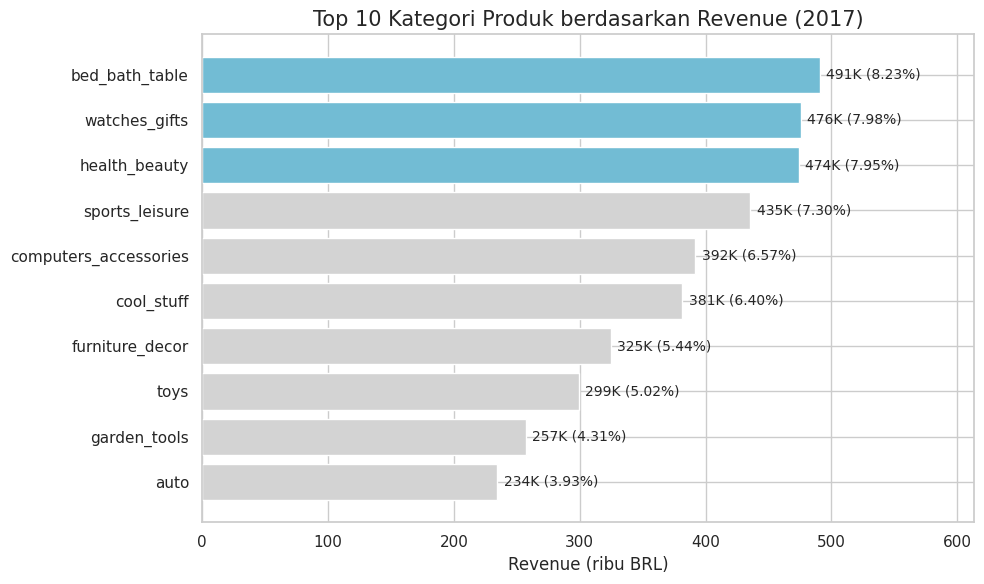

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = ["#72BCD4"] * 3 + ["#D3D3D3"] * 7
ax.barh(top10_df["product_category_name_english"], top10_df["revenue"] / 1000, color=colors)
ax.invert_yaxis()

for i, (rev, share) in enumerate(zip(top10_df["revenue"], top10_df["revenue_share_pct"])):
    ax.text(rev / 1000 + 5, i, f"{rev / 1000:,.0f}K ({share:.2f}%)", va="center", fontsize=10)

ax.set_title("Top 10 Kategori Produk berdasarkan Revenue (2017)", loc="center", fontsize=15)
ax.set_xlabel("Revenue (ribu BRL)")
ax.set_ylabel(None)
ax.set_xlim(0, top10_df["revenue"].max() / 1000 * 1.25)
plt.tight_layout()
plt.show()

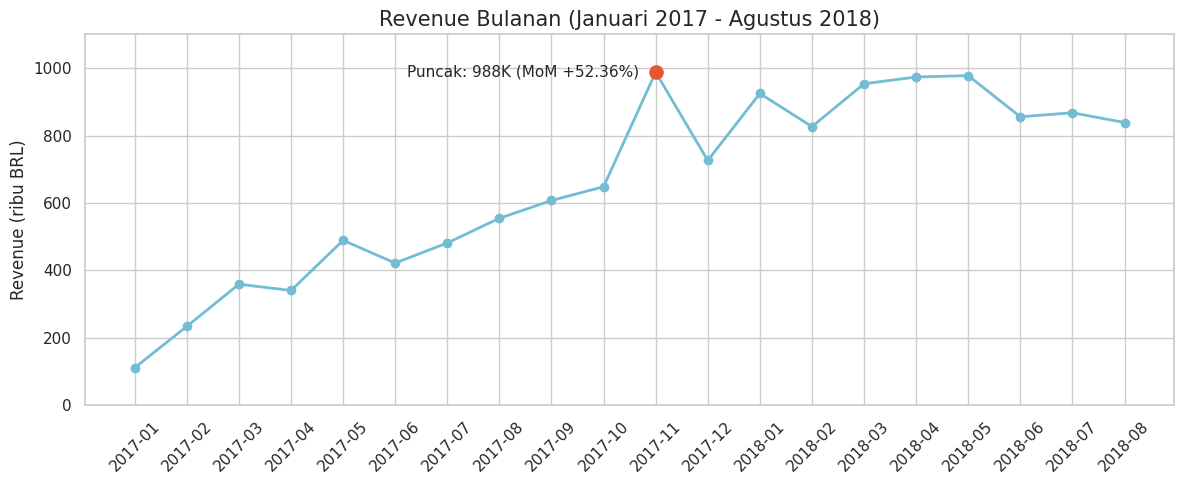

In [ ]:
monthly_plot_df = monthly_revenue_df.reset_index()
peak_idx = monthly_plot_df["revenue"].idxmax()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_plot_df["order_month"], monthly_plot_df["revenue"] / 1000,
        marker="o", linewidth=2, color="#72BCD4")
ax.scatter(monthly_plot_df.loc[peak_idx, "order_month"],
           monthly_plot_df.loc[peak_idx, "revenue"] / 1000,
           color="#E4572E", s=90, zorder=5)
ax.annotate(
    f"Puncak: {monthly_plot_df.loc[peak_idx, 'revenue'] / 1000:,.0f}K "
    f"(MoM {monthly_plot_df.loc[peak_idx, 'mom_growth_pct']:+.2f}%)",
    xy=(monthly_plot_df.loc[peak_idx, "order_month"], monthly_plot_df.loc[peak_idx, "revenue"] / 1000),
    xytext=(-12, 0), textcoords="offset points",
    ha="right", va="center", fontsize=11
)
ax.set_ylim(0, 1100)
ax.set_title("Revenue Bulanan (Januari 2017 - Agustus 2018)", loc="center", fontsize=15)
ax.set_ylabel("Revenue (ribu BRL)")
ax.set_xlabel(None)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

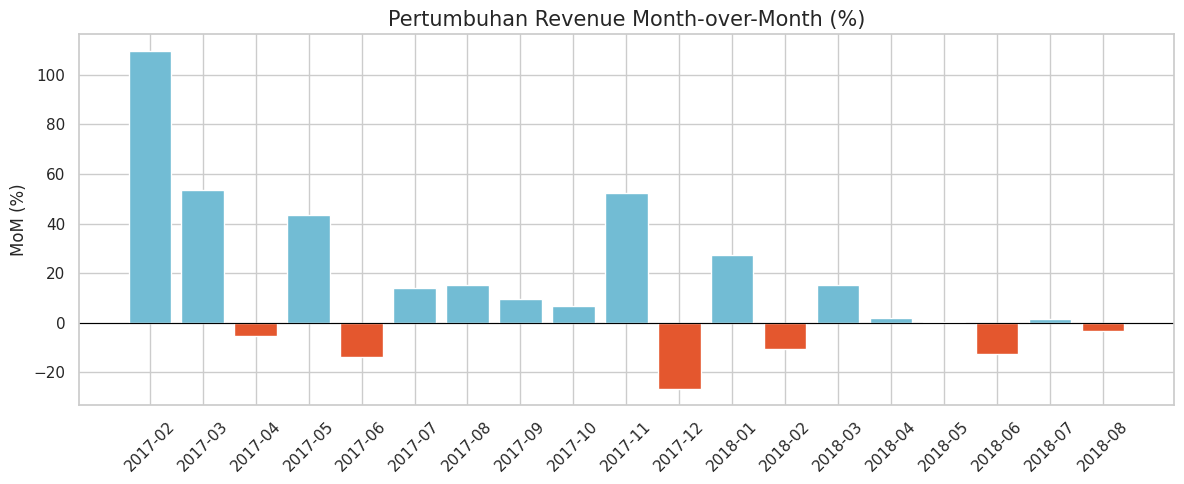

In [ ]:
mom_df = monthly_plot_df.dropna(subset=["mom_growth_pct"])
colors_mom = ["#72BCD4" if x >= 0 else "#E4572E" for x in mom_df["mom_growth_pct"]]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(mom_df["order_month"], mom_df["mom_growth_pct"], color=colors_mom)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Pertumbuhan Revenue Month-over-Month (%)", loc="center", fontsize=15)
ax.set_ylabel("MoM (%)")
ax.set_xlabel(None)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Catatan:** lonjakan MoM Februari 2017 (+109,51%) terjadi dari basis revenue yang masih sangat kecil, sehingga tidak mencerminkan pertumbuhan organik yang setara.

### Pertanyaan 2: Berapa selisih rata-rata review score antara pesanan tepat waktu dan terlambat selama Januari 2017 sampai Agustus 2018, dan di 5 state mana persentase keterlambatannya paling tinggi?

In [ ]:
status_order = ["Tepat waktu", "Telat 1-3 hari", "Telat >3 hari"]

status_review_df = (
    orders_unique_df.groupby("delivery_status")
    .agg(order_count=("order_id", "nunique"), avg_review_score=("review_score", "mean"))
    .reindex(status_order)
    .reset_index()
)
status_review_df

,delivery_status,order_count,avg_review_score
0,Tepat waktu,88381,4.294908
1,Telat 1-3 hari,2660,3.765844
2,Telat >3 hari,5162,1.935497


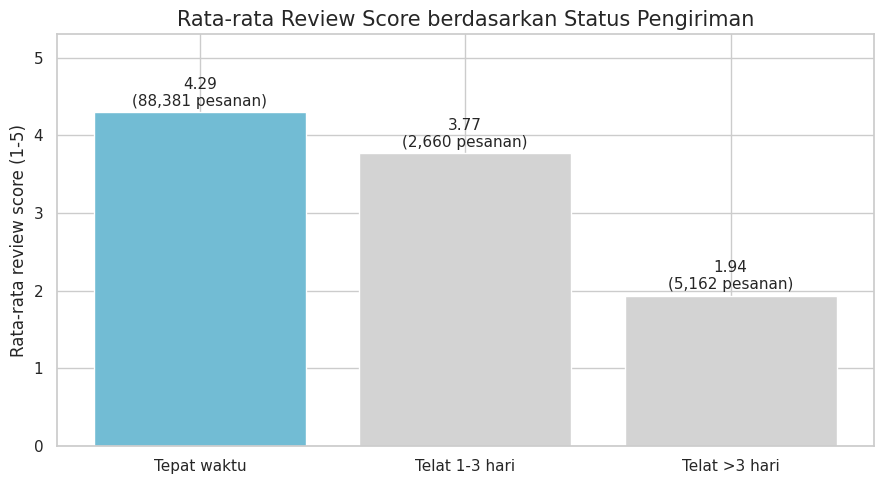

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

colors = ["#72BCD4", "#D3D3D3", "#D3D3D3"]
bars = ax.bar(status_review_df["delivery_status"], status_review_df["avg_review_score"], color=colors)

for bar, n in zip(bars, status_review_df["order_count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.08,
            f"{bar.get_height():.2f}\n({n:,} pesanan)", ha="center", fontsize=11)

ax.set_ylim(0, 5.3)
ax.set_title("Rata-rata Review Score berdasarkan Status Pengiriman", loc="center", fontsize=15)
ax.set_ylabel("Rata-rata review score (1-5)")
ax.set_xlabel(None)
plt.tight_layout()
plt.show()

In [ ]:
nasional_late_pct = orders_unique_df.is_late.mean() * 100
top5_state_df = state_late_df[state_late_df["order_count"] >= 100].head(5).reset_index()
print("Rata-rata nasional keterlambatan (%):", round(nasional_late_pct, 2))
top5_state_df

Rata-rata nasional keterlambatan (%): 8.13


,customer_state,order_count,late_count,late_pct
0,AL,396,95,23.99
1,MA,713,140,19.64
2,PI,475,76,16.00
3,CE,1273,196,15.40
4,SE,332,51,15.36


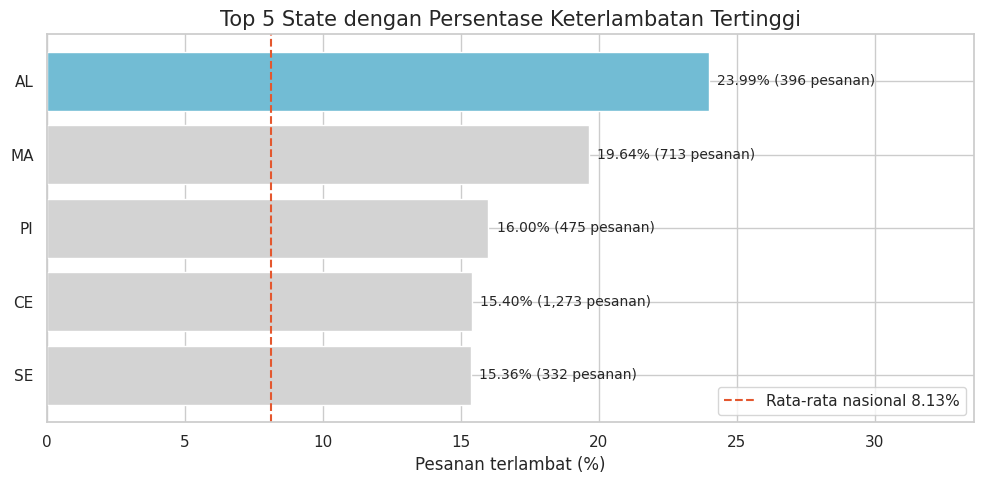

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

colors = ["#72BCD4"] + ["#D3D3D3"] * 4
ax.barh(top5_state_df["customer_state"], top5_state_df["late_pct"], color=colors)
ax.invert_yaxis()

for i, (pct, n) in enumerate(zip(top5_state_df["late_pct"], top5_state_df["order_count"])):
    ax.text(pct + 0.3, i, f"{pct:.2f}% ({n:,} pesanan)", va="center", fontsize=10)

ax.axvline(nasional_late_pct, color="#E4572E", linestyle="--", linewidth=1.5,
           label=f"Rata-rata nasional {nasional_late_pct:.2f}%")
ax.legend(loc="lower right")

ax.set_title("Top 5 State dengan Persentase Keterlambatan Tertinggi", loc="center", fontsize=15)
ax.set_xlabel("Pesanan terlambat (%)")
ax.set_ylabel(None)
ax.set_xlim(0, top5_state_df["late_pct"].max() * 1.4)
plt.tight_layout()
plt.show()

**Insight:**
- **Pertanyaan 1 (kategori):** revenue 2017 relatif tersebar. Tiga kategori teratas (`bed_bath_table`, `watches_gifts`, `health_beauty`) hampir seimbang di kisaran 8% per kategori, dan Top 10 menyumbang 63,13% dari total. `watches_gifts` bisa bersaing dengan jumlah pesanan lebih sedikit karena nilai per pesanannya tinggi.
- **Pertanyaan 1 (tren):** revenue cenderung naik sepanjang 2017 (dengan penurunan kecil di April dan Juni) hingga puncak November 2017 (988 ribu BRL; MoM +52,36%), yang kemungkinan terkait momen promosi akhir tahun, lalu turun 26,49% di Desember 2017. Sepanjang 2018 revenue mendatar di kisaran 826 ribu sampai 978 ribu BRL tanpa lonjakan baru, dan Juni sampai Agustus 2018 turun dari level April-Mei (sekitar 975 ribu menjadi 838 ribu pada Agustus).
- **Pertanyaan 2 (review):** pesanan tepat waktu mendapat rata-rata 4,29, sedangkan pesanan terlambat 2,57, selisih sekitar 1,7 poin. Penurunan terjadi bertahap: terlambat 1-3 hari turun ke 3,77 dan terlambat lebih dari 3 hari anjlok ke 1,94.
- **Pertanyaan 2 (state):** lima state dengan keterlambatan tertinggi adalah AL (23,99%), MA (19,64%), PI (16,00%), CE (15,40%), dan SE (15,36%). Semuanya berada di wilayah timur laut Brasil, dan AL hampir tiga kali lipat rata-rata nasional (8,13%).


### Pertanyaan 3:
Pertanyaan 3 dijawab pada bagian **Analisis Lanjutan** (RFM Analysis dan manual grouping).

## Analisis Lanjutan

### RFM Analysis (Pertanyaan 3)

Pelanggan diidentifikasi dengan `customer_unique_id` (bukan `customer_id`) agar pelanggan yang sama tidak dihitung sebagai orang berbeda.
- **Recency:** jumlah hari sejak pembelian terakhir terhadap tanggal transaksi terakhir di data
- **Frequency:** jumlah pesanan unik
- **Monetary:** total `price` seluruh pesanan (tidak termasuk ongkos kirim)

In [ ]:
recent_date = all_df["order_purchase_timestamp"].max()

rfm_df = all_df.groupby("customer_unique_id", as_index=False).agg(
    last_order=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum")
)
rfm_df["recency"] = (recent_date - rfm_df["last_order"]).dt.days
rfm_df.drop("last_order", axis=1, inplace=True)
rfm_df.head()

,customer_unique_id,frequency,monetary,recency
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,111
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,114
2,0000f46a3911fa3c0805444483337064,1,69.00,536
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,320
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,287


In [ ]:
rfm_df[["recency", "frequency", "monetary"]].describe().round(2)

,recency,frequency,monetary
count,93096.00,93096.00,93096.00
mean,235.71,1.03,141.57
std,150.94,0.21,215.77
min,0.00,1.00,0.85
25%,113.00,1.00,47.65
50%,217.00,1.00,89.70
75%,344.00,1.00,154.16
max,601.00,15.00,13440.00


In [ ]:
rfm_df.sort_values(by="monetary", ascending=False).head(5)

,customer_unique_id,frequency,monetary,recency
3716,0a0a92112bd4c708ca5fde585afaa872,1,13440.0,333
79413,da122df9eeddfedc1dc1f5349a1a690c,2,7388.0,514
43046,763c8b1c9c68a0229c42c9fc6f662b93,1,7160.0,45
80239,dc4802a71eae9be1dd28f5d788ceb526,1,6735.0,562
25355,459bef486812aa25204be022145caa62,1,6729.0,34


#### Segmentasi pelanggan dengan manual grouping

Karena 97% pelanggan hanya membeli satu kali, skor berbasis rank akan menghasilkan banyak nilai kembar. Karena itu segmen dibuat dengan aturan bisnis (manual grouping):

| Segmen | Aturan |
|---|---|
| Champions | Frequency ≥ 2 dan Recency ≤ 180 hari |
| Loyal Customers | Frequency ≥ 2 dan Recency > 180 hari |
| Recent Big Spenders | Frequency = 1, Recency ≤ 180 hari, Monetary ≥ kuartil 3 |
| Recent Customers | Frequency = 1 dan Recency ≤ 180 hari |
| At Risk | Frequency = 1 dan Recency 181-365 hari |
| Lost Customers | Frequency = 1 dan Recency > 365 hari |

In [ ]:
rfm_df["frequency_group"] = pd.cut(
    rfm_df["frequency"],
    bins=[0, 1, 2, np.inf],
    labels=["1 kali", "2 kali", "3 kali atau lebih"]
)
rfm_df["frequency_group"].value_counts()

,count
frequency_group,
1 kali,90307
2 kali,2562
3 kali atau lebih,227


In [ ]:
m_q75 = rfm_df["monetary"].quantile(0.75)
print("Batas Monetary kuartil 3:", round(m_q75, 2))

kondisi = [
    (rfm_df["frequency"] >= 2) & (rfm_df["recency"] <= 180),
    (rfm_df["frequency"] >= 2),
    (rfm_df["recency"] <= 180) & (rfm_df["monetary"] >= m_q75),
    (rfm_df["recency"] <= 180),
    (rfm_df["recency"] <= 365),
]
label = ["Champions", "Loyal Customers", "Recent Big Spenders", "Recent Customers", "At Risk"]

rfm_df["customer_segment"] = np.select(kondisi, label, default="Lost Customers")
rfm_df[["customer_unique_id", "recency", "frequency", "monetary", "customer_segment"]].head(10)

Batas Monetary kuartil 3: 154.16


,customer_unique_id,recency,frequency,monetary,customer_segment
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,129.90,Recent Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,18.90,Recent Customers
2,0000f46a3911fa3c0805444483337064,536,1,69.00,Lost Customers
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,25.99,At Risk
4,0004aac84e0df4da2b147fca70cf8255,287,1,180.00,At Risk
5,0004bd2a26a76fe21f786e4fbd80607f,145,1,154.00,Recent Customers
6,00050ab1314c0e55a6ca13cf7181fecf,131,1,27.99,Recent Customers
7,00053a61a98854899e70ed204dd4bafe,182,1,382.00,At Risk
8,0005e1862207bf6ccc02e4228effd9a0,542,1,135.00,Lost Customers
9,0005ef4cd20d2893f0d9fbd94d3c0d97,169,1,104.90,Recent Customers


In [ ]:
segment_order = ["Champions", "Loyal Customers", "Recent Big Spenders",
                 "Recent Customers", "At Risk", "Lost Customers"]

segment_df = rfm_df.groupby("customer_segment").agg(
    customer_count=("customer_unique_id", "nunique"),
    total_revenue=("monetary", "sum"),
    avg_monetary=("monetary", "mean"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean")
).reindex(segment_order)

segment_df["customer_pct"] = segment_df["customer_count"] / segment_df["customer_count"].sum() * 100
segment_df["revenue_pct"] = segment_df["total_revenue"] / segment_df["total_revenue"].sum() * 100
segment_df.round(2)

,customer_count,total_revenue,avg_monetary,avg_recency,avg_frequency,customer_pct,revenue_pct
customer_segment,,,,,,,
Champions,1237,332603.37,268.88,90.39,2.15,1.33,2.52
Loyal Customers,1552,392751.67,253.06,320.78,2.08,1.67,2.98
Recent Big Spenders,8931,3197214.74,357.99,93.06,1.00,9.59,24.26
Recent Customers,28178,2008342.18,71.27,91.34,1.00,30.27,15.24
At Risk,33348,4542789.67,136.22,263.58,1.00,35.82,34.47
Lost Customers,19850,2706076.32,136.33,460.42,1.00,21.32,20.53


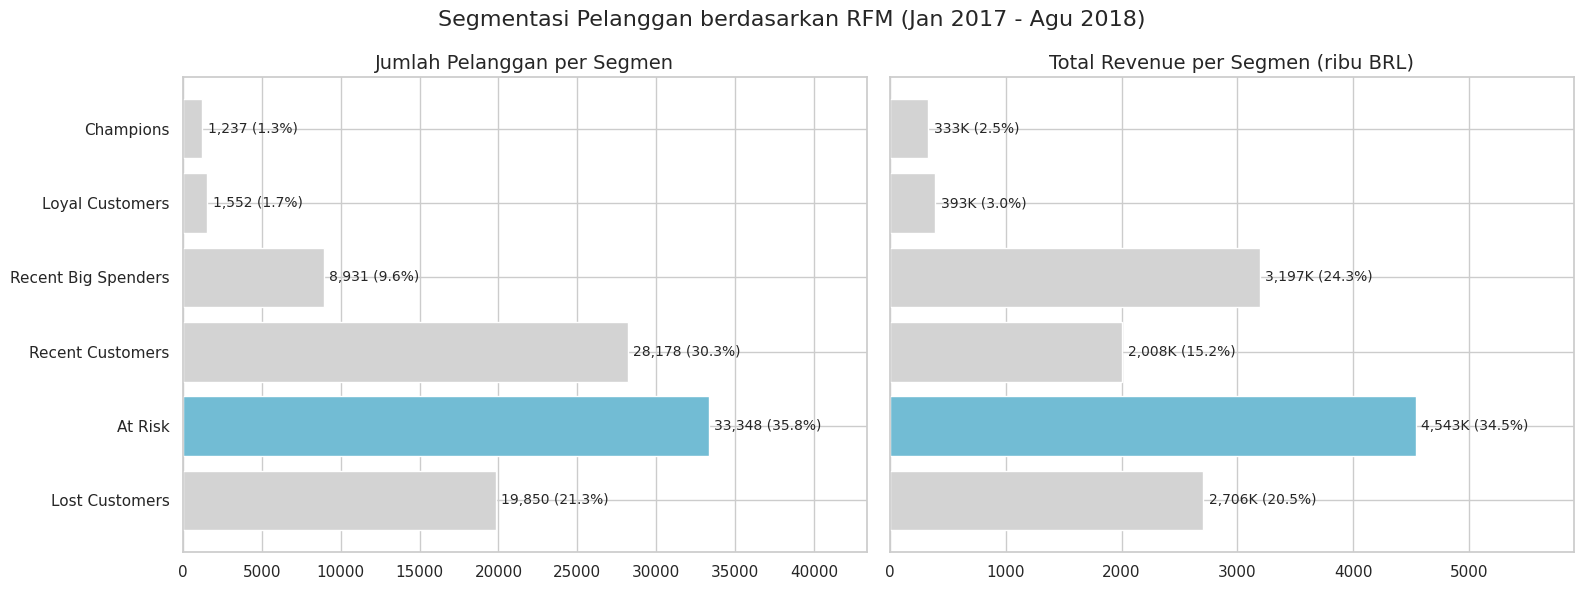

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Jumlah pelanggan per segmen
colors_cnt = ["#72BCD4" if v == segment_df["customer_count"].max() else "#D3D3D3" for v in segment_df["customer_count"]]
ax[0].barh(segment_df.index, segment_df["customer_count"], color=colors_cnt)
ax[0].invert_yaxis()
for i, (n, p) in enumerate(zip(segment_df["customer_count"], segment_df["customer_pct"])):
    ax[0].text(n + segment_df["customer_count"].max() * 0.01, i, f"{n:,} ({p:.1f}%)", va="center", fontsize=10)
ax[0].set_title("Jumlah Pelanggan per Segmen", fontsize=14)
ax[0].set_xlim(0, segment_df["customer_count"].max() * 1.3)
ax[0].set_xlabel(None)

# Revenue per segmen
colors_rev = ["#72BCD4" if v == segment_df["total_revenue"].max() else "#D3D3D3" for v in segment_df["total_revenue"]]
ax[1].barh(segment_df.index, segment_df["total_revenue"] / 1000, color=colors_rev)
ax[1].invert_yaxis()
for i, (r, p) in enumerate(zip(segment_df["total_revenue"], segment_df["revenue_pct"])):
    ax[1].text(r / 1000 + segment_df["total_revenue"].max() / 1000 * 0.01, i, f"{r / 1000:,.0f}K ({p:.1f}%)", va="center", fontsize=10)
ax[1].set_title("Total Revenue per Segmen (ribu BRL)", fontsize=14)
ax[1].set_xlim(0, segment_df["total_revenue"].max() / 1000 * 1.3)
ax[1].set_xlabel(None)
ax[1].set_yticklabels([])

plt.suptitle("Segmentasi Pelanggan berdasarkan RFM (Jan 2017 - Agu 2018)", fontsize=16)
plt.tight_layout()
plt.show()

### Geospatial Analysis (Pertanyaan 2)

Peta menampilkan persentase keterlambatan per state. Titik pusat tiap state dihitung dari rata-rata koordinat zip code di `geolocation_df`, dengan membuang koordinat di luar wilayah Brasil (data koordinat Olist memuat sebagian titik yang tidak valid). Ukuran lingkaran menunjukkan jumlah pesanan, warna menunjukkan tingkat keterlambatan.

In [ ]:
geo_valid_df = geolocation_df[
    geolocation_df["geolocation_lat"].between(-34, 6) &
    geolocation_df["geolocation_lng"].between(-74, -34)
]
print("Zip code dibuang karena di luar Brasil:", len(geolocation_df) - len(geo_valid_df))

state_geo_df = geo_valid_df.groupby("geolocation_state").agg(
    lat=("geolocation_lat", "mean"),
    lng=("geolocation_lng", "mean")
).reset_index()
state_geo_df.head()

Zip code dibuang karena di luar Brasil: 11


,geolocation_state,lat,lng
0,AC,-9.993683,-68.281475
1,AL,-9.626957,-36.334846
2,AM,-3.463810,-61.352119
3,AP,-0.242076,-51.346698
4,BA,-13.016168,-39.631417


In [ ]:
state_map_df = state_late_df.reset_index().merge(
    state_geo_df, left_on="customer_state", right_on="geolocation_state", how="left"
)
print("Missing koordinat:", state_map_df["lat"].isna().sum())
state_map_df.sort_values("late_pct", ascending=False).head(10)

Missing koordinat: 0


,customer_state,order_count,late_count,late_pct,geolocation_state,lat,lng
0,AL,396,95,23.99,AL,-9.626957,-36.334846
1,MA,713,140,19.64,MA,-3.975372,-44.826805
2,PI,475,76,16.00,PI,-6.118110,-42.459016
3,CE,1273,196,15.40,CE,-4.628050,-39.124389
4,SE,332,51,15.36,SE,-10.760117,-37.201968
5,BA,3253,457,14.05,BA,-13.016168,-39.631417
6,RJ,12310,1664,13.52,RJ,-22.617709,-43.188254
7,TO,274,35,12.77,TO,-9.408054,-48.293926
8,RR,40,5,12.50,RR,2.601506,-60.608856
9,PA,942,117,12.42,PA,-2.703606,-49.526780


In [ ]:
def kategori_risiko(pct):
    if pct >= 15:
        return "Tinggi (>=15%)", "#E4572E"
    elif pct >= nasional_late_pct:
        return "Sedang (di atas rata-rata nasional)", "#F2A541"
    return "Rendah (di bawah rata-rata nasional)", "#72BCD4"

peta = folium.Map(
    location=[-14.2, -51.9],
    zoom_start=4,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri"
)

for _, r in state_map_df.iterrows():
    risiko, warna = kategori_risiko(r["late_pct"])
    folium.CircleMarker(
        location=[r["lat"], r["lng"]],
        radius=4 + r["order_count"] ** 0.5 / 12,
        color=warna, fill=True, fill_color=warna, fill_opacity=0.7,
        tooltip=f"{r['customer_state']}: {r['late_pct']:.2f}% terlambat ({r['order_count']:,} pesanan)"
    ).add_to(peta)

legend_html = """
<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white;
            padding: 10px; border: 1px solid #999; font-size: 12px;">
<b>Tingkat keterlambatan</b><br>
<span style="color:#E4572E;">&#9679;</span> Tinggi (>=15%)<br>
<span style="color:#F2A541;">&#9679;</span> Sedang (di atas rata-rata nasional)<br>
<span style="color:#72BCD4;">&#9679;</span> Rendah (di bawah rata-rata nasional)
</div>
"""
peta.get_root().html.add_child(folium.Element(legend_html))
peta

In [ ]:
state_map_df[["customer_state", "order_count", "late_count", "late_pct", "lat", "lng"]].to_csv(
    "dashboard/state_geo.csv", index=False
)

In [ ]:
state_map_df.sort_values("order_count", ascending=False).head(5)[["customer_state", "order_count", "late_count", "late_pct"]]

,customer_state,order_count,late_count,late_pct
20,SP,40399,2384,5.90
6,RJ,12310,1664,13.52
21,MG,11319,637,5.63
17,RS,5327,382,7.17
22,PR,4903,246,5.02


**Insight:**
- **RFM:** dari 93.096 pelanggan unik, segmen terbesar sekaligus penyumbang revenue terbesar adalah At Risk (33.348 pelanggan; 35,82%) dengan revenue 4,54 juta BRL (34,47% dari total).
- **Nilai per pelanggan:** segmen Recent Big Spenders hanya 9,59% pelanggan, tetapi menyumbang 24,26% revenue (rata-rata 358 BRL per pelanggan, jauh di atas Recent Customers yang hanya 71 BRL). Segmen ini perlu dijaga agar tidak turun ke At Risk.
- **Pelanggan loyal:** Champions dan Loyal Customers (Frequency ≥ 2) hanya 3,00% pelanggan dan 5,50% revenue. Pertumbuhan revenue selama ini bergantung pada pelanggan baru, bukan pelanggan berulang.
- **Risiko churn:** 57,14% pelanggan berada di segmen At Risk dan Lost Customers (lebih dari 180 hari tidak berbelanja), dengan total 55,0% revenue. Sebagian besar pelanggan hanya membeli satu kali (97,0%).
- **Sebaran nilai belanja:** rata-rata Monetary (141,57 BRL) jauh di atas median (89,70 BRL) dan nilai maksimum mencapai 13.440 BRL, menandakan segelintir pelanggan dengan belanja sangat besar.
- **Geospatial:** lima state dengan risiko tinggi (AL, MA, PI, CE, SE) seluruhnya berada di timur laut Brasil. Namun secara jumlah absolut, RJ memiliki 1.664 pesanan terlambat (13,52% dari 12.310 pesanan), lebih banyak dari gabungan lima state berisiko tinggi tersebut (558 pesanan). BA (14,05%; 457 pesanan terlambat) juga berada di atas rata-rata nasional 8,13%.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada 2017, revenue relatif tersebar di banyak kategori. Tiga kategori teratas hampir seimbang, yaitu `bed_bath_table` (490,6 ribu BRL; 8,23%), `watches_gifts` (475,6 ribu BRL; 7,98%), dan `health_beauty` (473,8 ribu BRL; 7,95%), sedangkan Top 10 kategori menyumbang 63,13% dari total revenue. `watches_gifts` bisa bersaing dengan jumlah pesanan yang jauh lebih sedikit (2.073 dibanding 4.423 milik `bed_bath_table`) karena nilai per pesanannya sekitar dua kali lipat. Untuk tren bulanan, revenue naik dari 111,8 ribu BRL (Januari 2017) ke puncak sekitar 988 ribu BRL pada November 2017 (MoM +52,36%), lalu turun 26,49% di Desember 2017. Sepanjang 2018 revenue mendatar di kisaran 826 ribu sampai 978 ribu BRL dan turun ke 838,6 ribu BRL pada Agustus 2018, sehingga pertumbuhan sudah melambat dibanding 2017.
- **Conclusion pertanyaan 2:** Keterlambatan pengiriman berkaitan dengan penurunan kepuasan pelanggan yang tajam. Rata-rata review score pesanan tepat waktu adalah 4,29, sedangkan pesanan terlambat 2,57, selisih sekitar 1,7 poin. Penurunannya bertahap: terlambat 1-3 hari mendapat 3,77, dan terlambat lebih dari 3 hari anjlok ke 1,94. Secara keseluruhan 8,13% pesanan terlambat. Lima state dengan persentase keterlambatan tertinggi (minimal 100 pesanan) adalah AL (23,99%), MA (19,64%), PI (16,00%), CE (15,40%), dan SE (15,36%), seluruhnya di timur laut Brasil. Dari sisi jumlah absolut, RJ memiliki 1.664 pesanan terlambat (13,52%), lebih banyak daripada gabungan kelima state tersebut (558 pesanan).
- **Conclusion pertanyaan 3:** Dari 93.096 pelanggan unik, 97,0% hanya membeli satu kali. Segmen terbesar sekaligus penyumbang revenue terbesar adalah At Risk (33.348 pelanggan; 35,82%) dengan revenue 4,54 juta BRL (34,47%). Segmen Recent Big Spenders hanya 9,59% pelanggan tetapi menyumbang 24,26% revenue, sedangkan Champions dan Loyal Customers digabung hanya 3,00% pelanggan dan 5,50% revenue. Sebanyak 57,14% pelanggan berada di segmen At Risk dan Lost Customers. Artinya, revenue sangat bergantung pada pembelian pertama dan basis pelanggan berulang masih sangat kecil.

**Rekomendasi Action Item:**
- **Perbaiki logistik di wilayah berisiko tinggi.** Tim operasional memprioritaskan AL, MA, PI, CE, dan SE (keterlambatan 15-24%, jauh di atas rata-rata nasional 8,13%) dengan menambah mitra kurir regional atau titik distribusi, serta menyesuaikan estimasi tanggal tiba yang ditampilkan ke pelanggan. Untuk RJ dan BA, fokusnya pada volume: RJ punya 1.664 pesanan terlambat sehingga pengurangan sedikit saja berdampak besar. Target yang bisa dipantau: turunkan persentase keterlambatan 5 state tersebut mendekati rata-rata nasional.
- **Cegah keterlambatan menjadi keterlambatan lebih dari 3 hari.** Review score jatuh dari 3,77 (telat 1-3 hari) ke 1,94 (telat lebih dari 3 hari). Tim layanan pelanggan sebaiknya mengirim notifikasi proaktif dan eskalasi ke seller atau kurir begitu pesanan melewati estimasi tanggal tiba, sebelum melewati 3 hari.
- **Jalankan kampanye win-back untuk segmen At Risk.** Segmen ini menyumbang 34,47% revenue dan masih dalam rentang 181-365 hari sejak pembelian terakhir, sehingga lebih mudah diaktifkan kembali dibanding Lost Customers. Gunakan voucher atau rekomendasi produk berdasarkan kategori yang pernah dibeli.
- **Dorong pembelian kedua dari Recent Customers dan Recent Big Spenders.** Karena 97,0% pelanggan hanya membeli sekali, berikan insentif pembelian berikutnya (misalnya voucher dengan masa berlaku terbatas) kepada pelanggan yang baru membeli dalam 180 hari terakhir, terutama Recent Big Spenders yang rata-rata belanjanya 358 BRL.
- **Prioritaskan stok dan promosi pada kategori unggulan.** Pastikan ketersediaan stok `bed_bath_table`, `watches_gifts`, dan `health_beauty`. Kategori `watches_gifts` layak diprioritaskan untuk promosi bernilai tinggi karena nilai per pesanannya paling besar di Top 3.
- **Siapkan perencanaan musiman untuk akhir tahun.** November 2017 adalah puncak revenue (+52,36% MoM), sementara 2018 cenderung mendatar. Tim pemasaran perlu menyiapkan kampanye dan kapasitas logistik untuk November, karena lonjakan pesanan juga meningkatkan risiko keterlambatan.